In [19]:
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import os

# 1. Nature Requirement: Keep text as editable font
plt.rcParams['svg.fonttype'] = 'none'

# 2. Define the Universal Patch
if not hasattr(Figure, '_original_savefig'):
    Figure._original_savefig = Figure.savefig

def universal_svg_patch(self, fname, *args, **kwargs):
    # Execute the original intended save (PNG/JPG)
    self._original_savefig(fname, *args, **kwargs)

    # Check if we should create an SVG twin
    if isinstance(fname, (str, os.PathLike)) and not str(fname).endswith('.svg'):
        # Convert path to string and swap extension
        base_path = os.path.splitext(str(fname))[0]
        svg_name = f"{base_path}.svg"

        # Clean up kwargs (SVG doesn't use DPI)
        svg_kwargs = kwargs.copy()
        svg_kwargs.pop('dpi', None)
        svg_kwargs['format'] = 'svg'

        try:
            print(f"🚀 Universal Vector Export: {svg_name}")
            self._original_savefig(svg_name, *args, **svg_kwargs)
        except Exception as e:
            print(f"⚠️ SVG Export Failed for {fname}: {e}")

# 3. Apply the patch to the base Figure class
Figure.savefig = universal_svg_patch

In [20]:
# Install packages if needed
# !pip install umap-learn openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

from scipy.stats import skew, kurtosis
from scipy.spatial.distance import mahalanobis
from scipy.linalg import inv

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11


In [21]:
# Load dataset

FILE_PATH = 'dataset.xlsx'

df = pd.read_excel(FILE_PATH)

print('Dataset shape:', df.shape)
display(df.head())


Dataset shape: (62, 23)


,Half life_matrix_avg,logKOC_matrix_avg,Cellulose_Percentage,Hemicellulose_Percentage,Lignin_Percentage,Half life_fiber_avg,logKOC_fiber_avg,fiber_rotatable_bond_count,tortuosity,Specific Interface Area,...,sol_mismatch,fiber_sol_parameter,matrix_sol_parameter,fiber_CED,matrix_CED,hydrophyllic_gradient,flory_huggins,fiber_dia_or_average_particle_size_mm,first_order_rate,hixson_rate
0,1.040000,3.456000,38.0,20.0,27.0,0.558941,2.034941,1.33,1.000000,1.029703,...,5.4088,49.54,50.37,2537.00,521.28,22.80,758.52,2.525,0.00161,0.00049
1,0.642162,1.225676,55.2,16.8,25.3,0.561346,2.065807,1.30,1.000000,0.800000,...,1.0502,50.10,41.59,2510.30,1729.67,4.31,72.42,1.000,0.01695,0.00533
2,0.675714,1.693878,78.0,10.0,8.0,0.566250,2.109792,1.04,2.607143,1.714286,...,0.5500,50.34,38.32,2533.71,1468.70,7.34,144.30,0.350,0.00112,0.00035
3,0.780000,1.750000,32.5,30.0,26.0,0.557345,1.994576,1.17,4386.964912,7.017544,...,3.0100,51.07,16.41,2608.56,269.14,28.52,1201.92,0.285,0.00181,0.00059
4,0.780000,1.750000,76.0,0.0,8.5,0.567988,2.150947,1.20,1667.666667,2.666667,...,4.0700,49.71,16.41,2471.42,269.14,29.88,1109.43,0.150,0.00117,0.00038


# 1. Descriptor Summary Table

This table explains the **range and spread** of every descriptor.


In [22]:
numeric_df = df.select_dtypes(include=np.number)

summary_table = pd.DataFrame({
    'Min': numeric_df.min(),
    'Max': numeric_df.max(),
    'Mean': numeric_df.mean(),
    'Median': numeric_df.median(),
    'Std': numeric_df.std(),
    'Q1': numeric_df.quantile(0.25),
    'Q3': numeric_df.quantile(0.75),
    'Skewness': numeric_df.apply(skew),
    'Kurtosis': numeric_df.apply(kurtosis),
    'Missing': numeric_df.isnull().sum(),
    'Unique Values': numeric_df.nunique()
})

display(summary_table)

summary_table.to_csv('descriptor_summary_statistics.csv')


,Min,Max,Mean,Median,Std,Q1,Q3,Skewness,Kurtosis,Missing,Unique Values
Half life_matrix_avg,0.550000,1.940000,0.807570,0.665000,0.383870,0.620000,0.780000,2.131116,3.136766,0,17
logKOC_matrix_avg,1.040000,5.000000,1.956947,1.710000,1.118292,1.340000,1.780000,1.686093,1.655453,0,18
Cellulose_Percentage,26.600000,100.000000,58.248387,65.000000,19.657875,38.000000,71.000000,0.105740,-0.947495,0,21
Hemicellulose_Percentage,0.000000,38.000000,17.233226,19.600000,11.264617,10.000000,26.275000,-0.086408,-0.822469,0,19
Lignin_Percentage,0.000000,43.000000,15.537097,10.250000,12.464681,5.625000,25.825000,0.574110,-0.662234,0,21
Half life_fiber_avg,0.556356,0.570000,0.562697,0.563830,0.003858,0.559079,0.565302,-0.044586,-1.047864,0,25
logKOC_fiber_avg,1.980816,2.160000,2.067192,2.071272,0.051896,2.033511,2.108286,-0.074959,-0.813864,0,25
fiber_rotatable_bond_count,0.650000,2.210000,1.148197,1.020000,0.364497,0.980000,1.240000,NaN,NaN,1,23
tortuosity,1.000000,11112.111111,2067.256813,999.863636,2858.948116,8.276786,2746.098039,1.724382,2.238339,0,46
Specific Interface Area,0.250000,188.235294,22.900770,7.008772,41.069522,3.153846,14.344828,2.631831,6.568519,0,52


# 2. Descriptor Distribution Histograms

🚀 Universal Vector Export: all_descriptor_histograms.svg


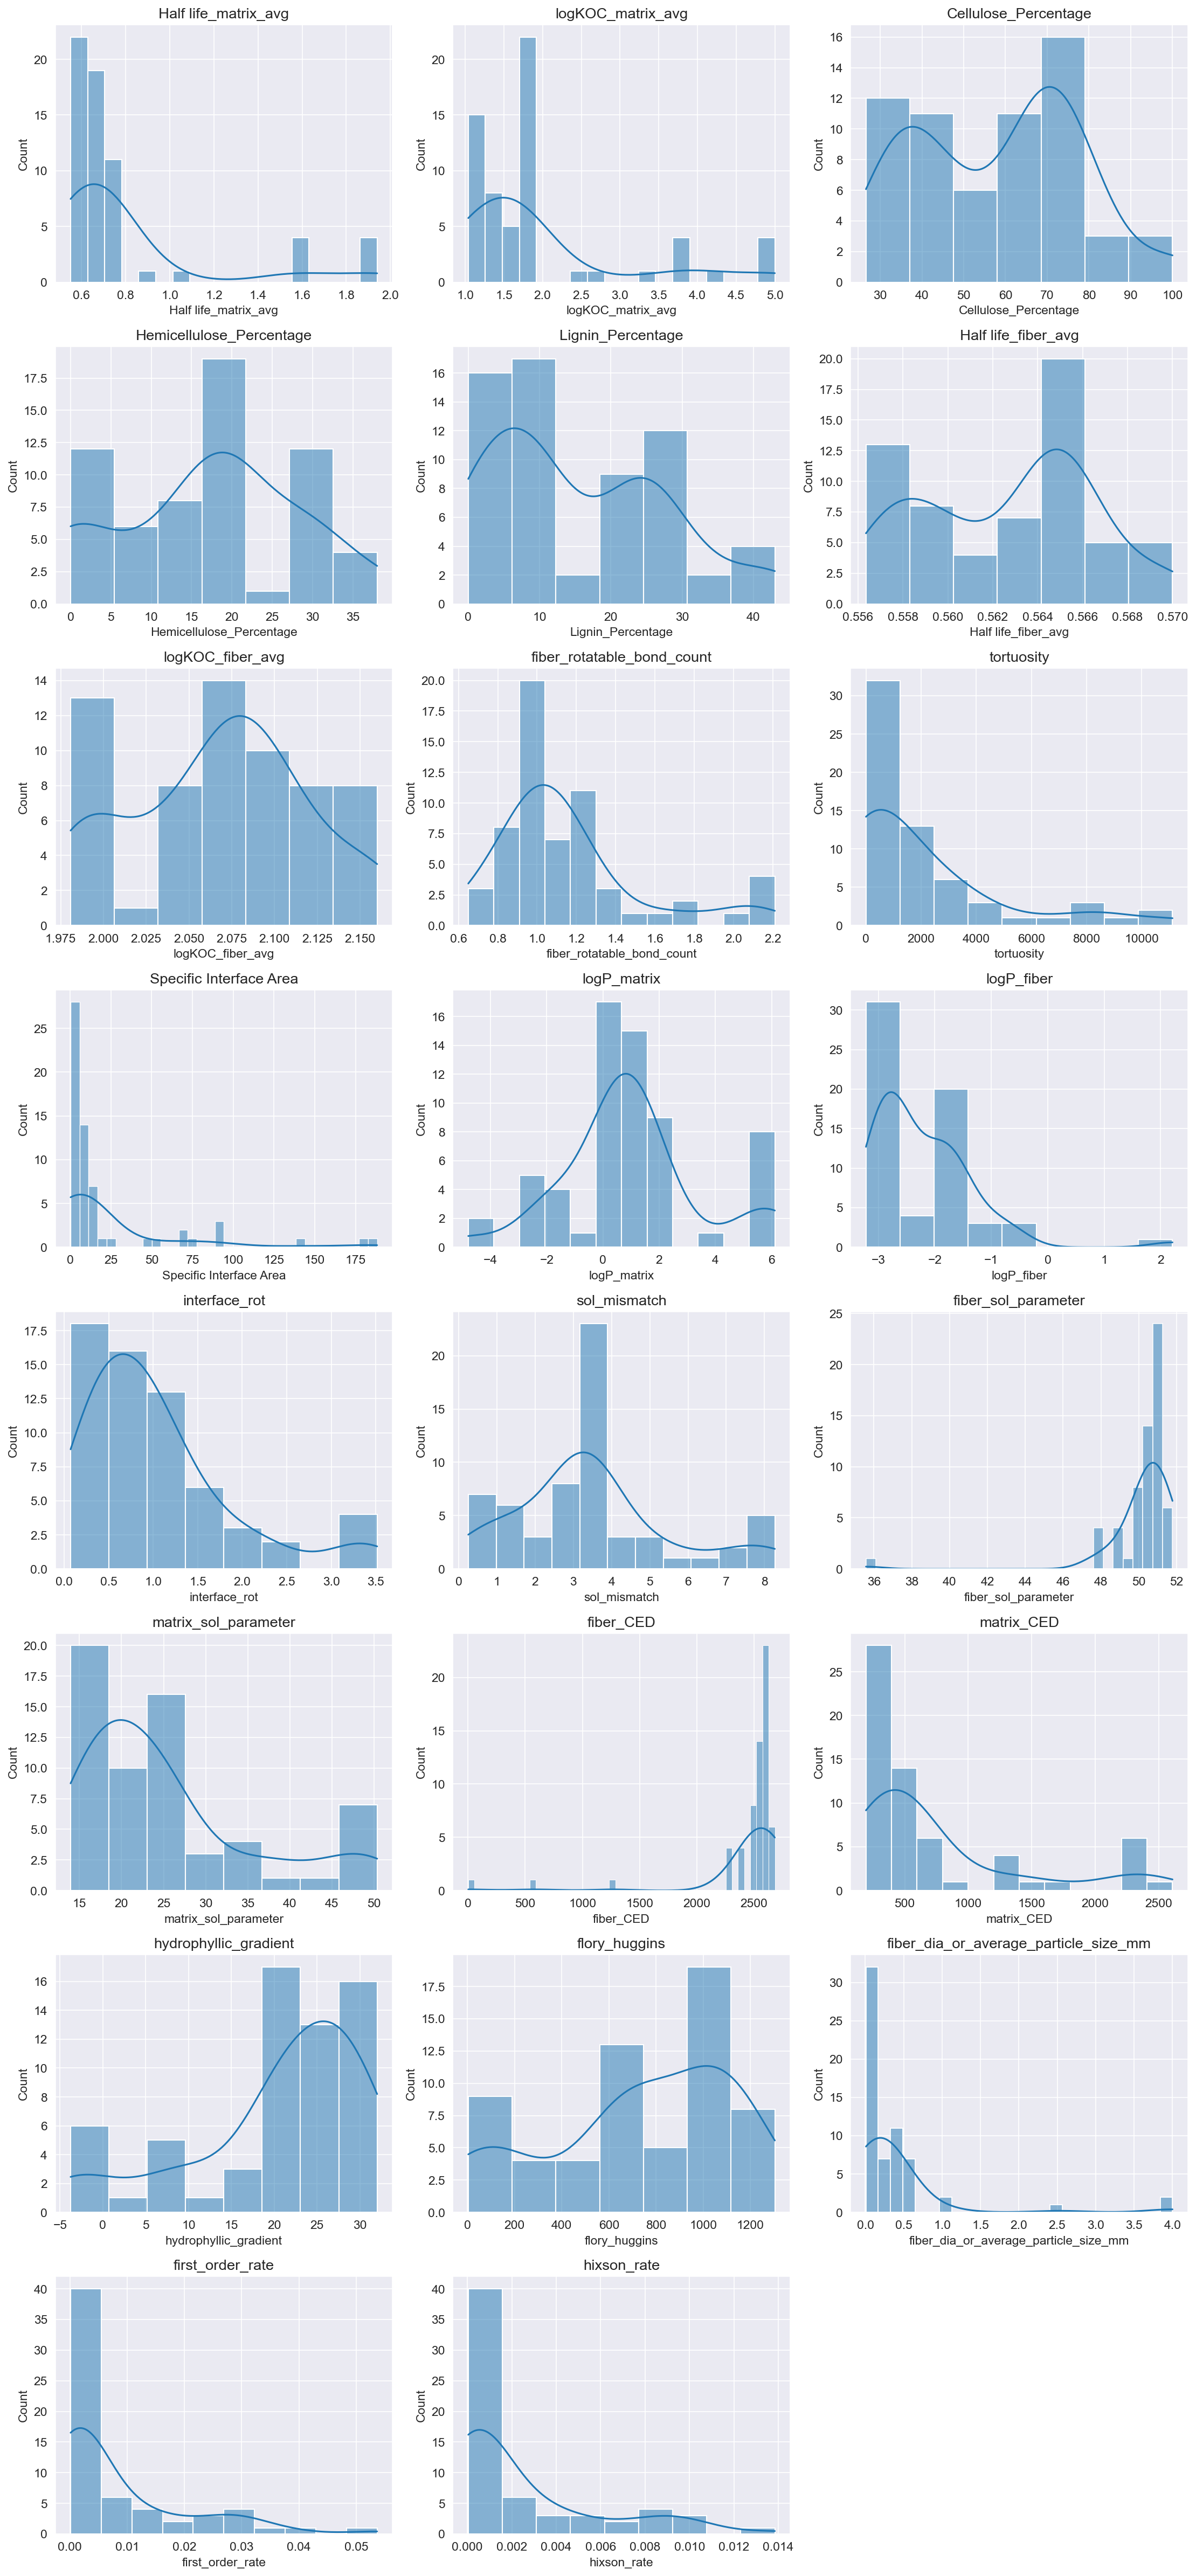

In [23]:
n_cols = 3
n_features = len(numeric_df.columns)
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_df.columns):
    sns.histplot(numeric_df[col], kde=True, ax=axes[i])
    axes[i].set_title(col)

for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('all_descriptor_histograms.png', bbox_inches='tight')
plt.show()


# 3. Standardized Boxplots

Useful for:
- comparing descriptor spread
- identifying outliers
- visualizing heterogeneity


🚀 Universal Vector Export: descriptor_boxplots.svg


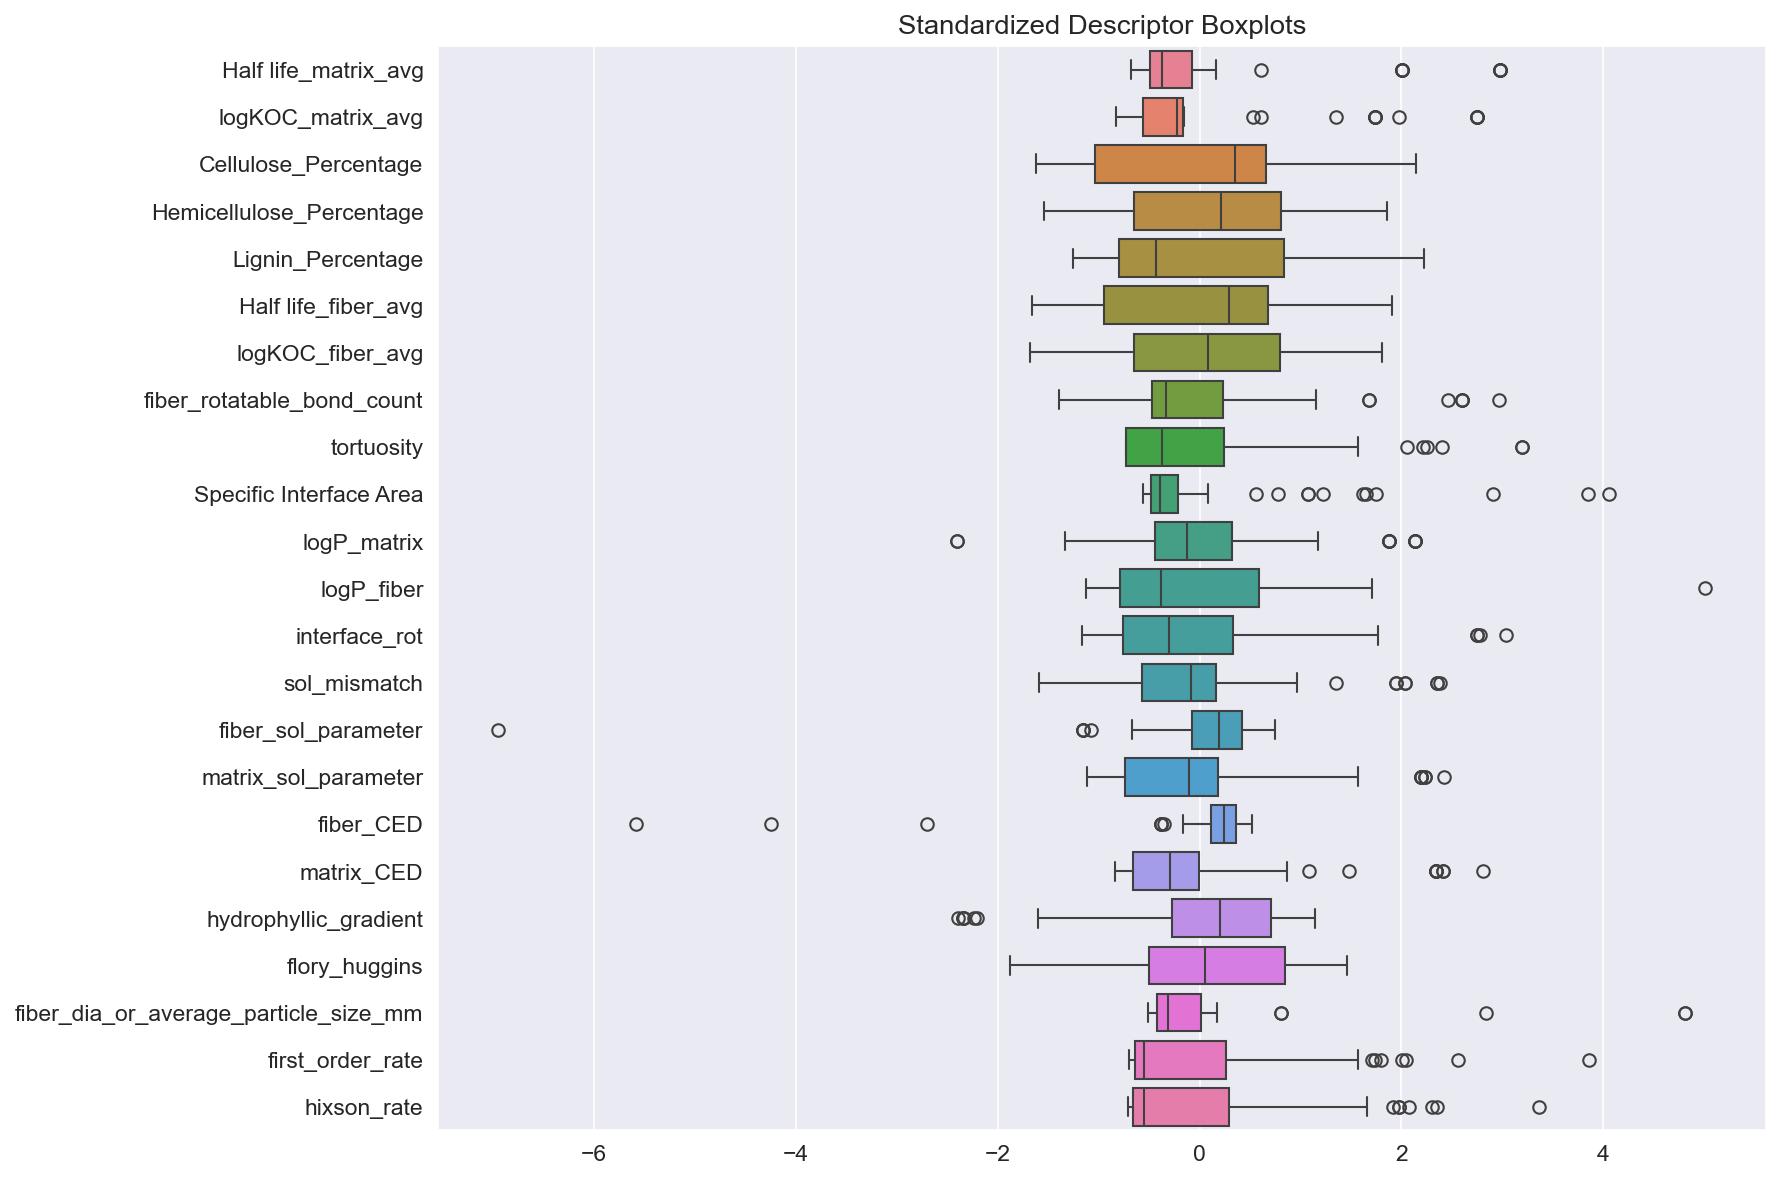

In [24]:
scaler = StandardScaler()

scaled = scaler.fit_transform(numeric_df.fillna(numeric_df.mean()))
scaled_df = pd.DataFrame(scaled, columns=numeric_df.columns)

plt.figure(figsize=(12, 8))
sns.boxplot(data=scaled_df, orient='h')

plt.title('Standardized Descriptor Boxplots')
plt.tight_layout()

plt.savefig('descriptor_boxplots.png', bbox_inches='tight')
plt.show()


# 4. Pearson Correlation Heatmap

🚀 Universal Vector Export: pearson_heatmap.svg


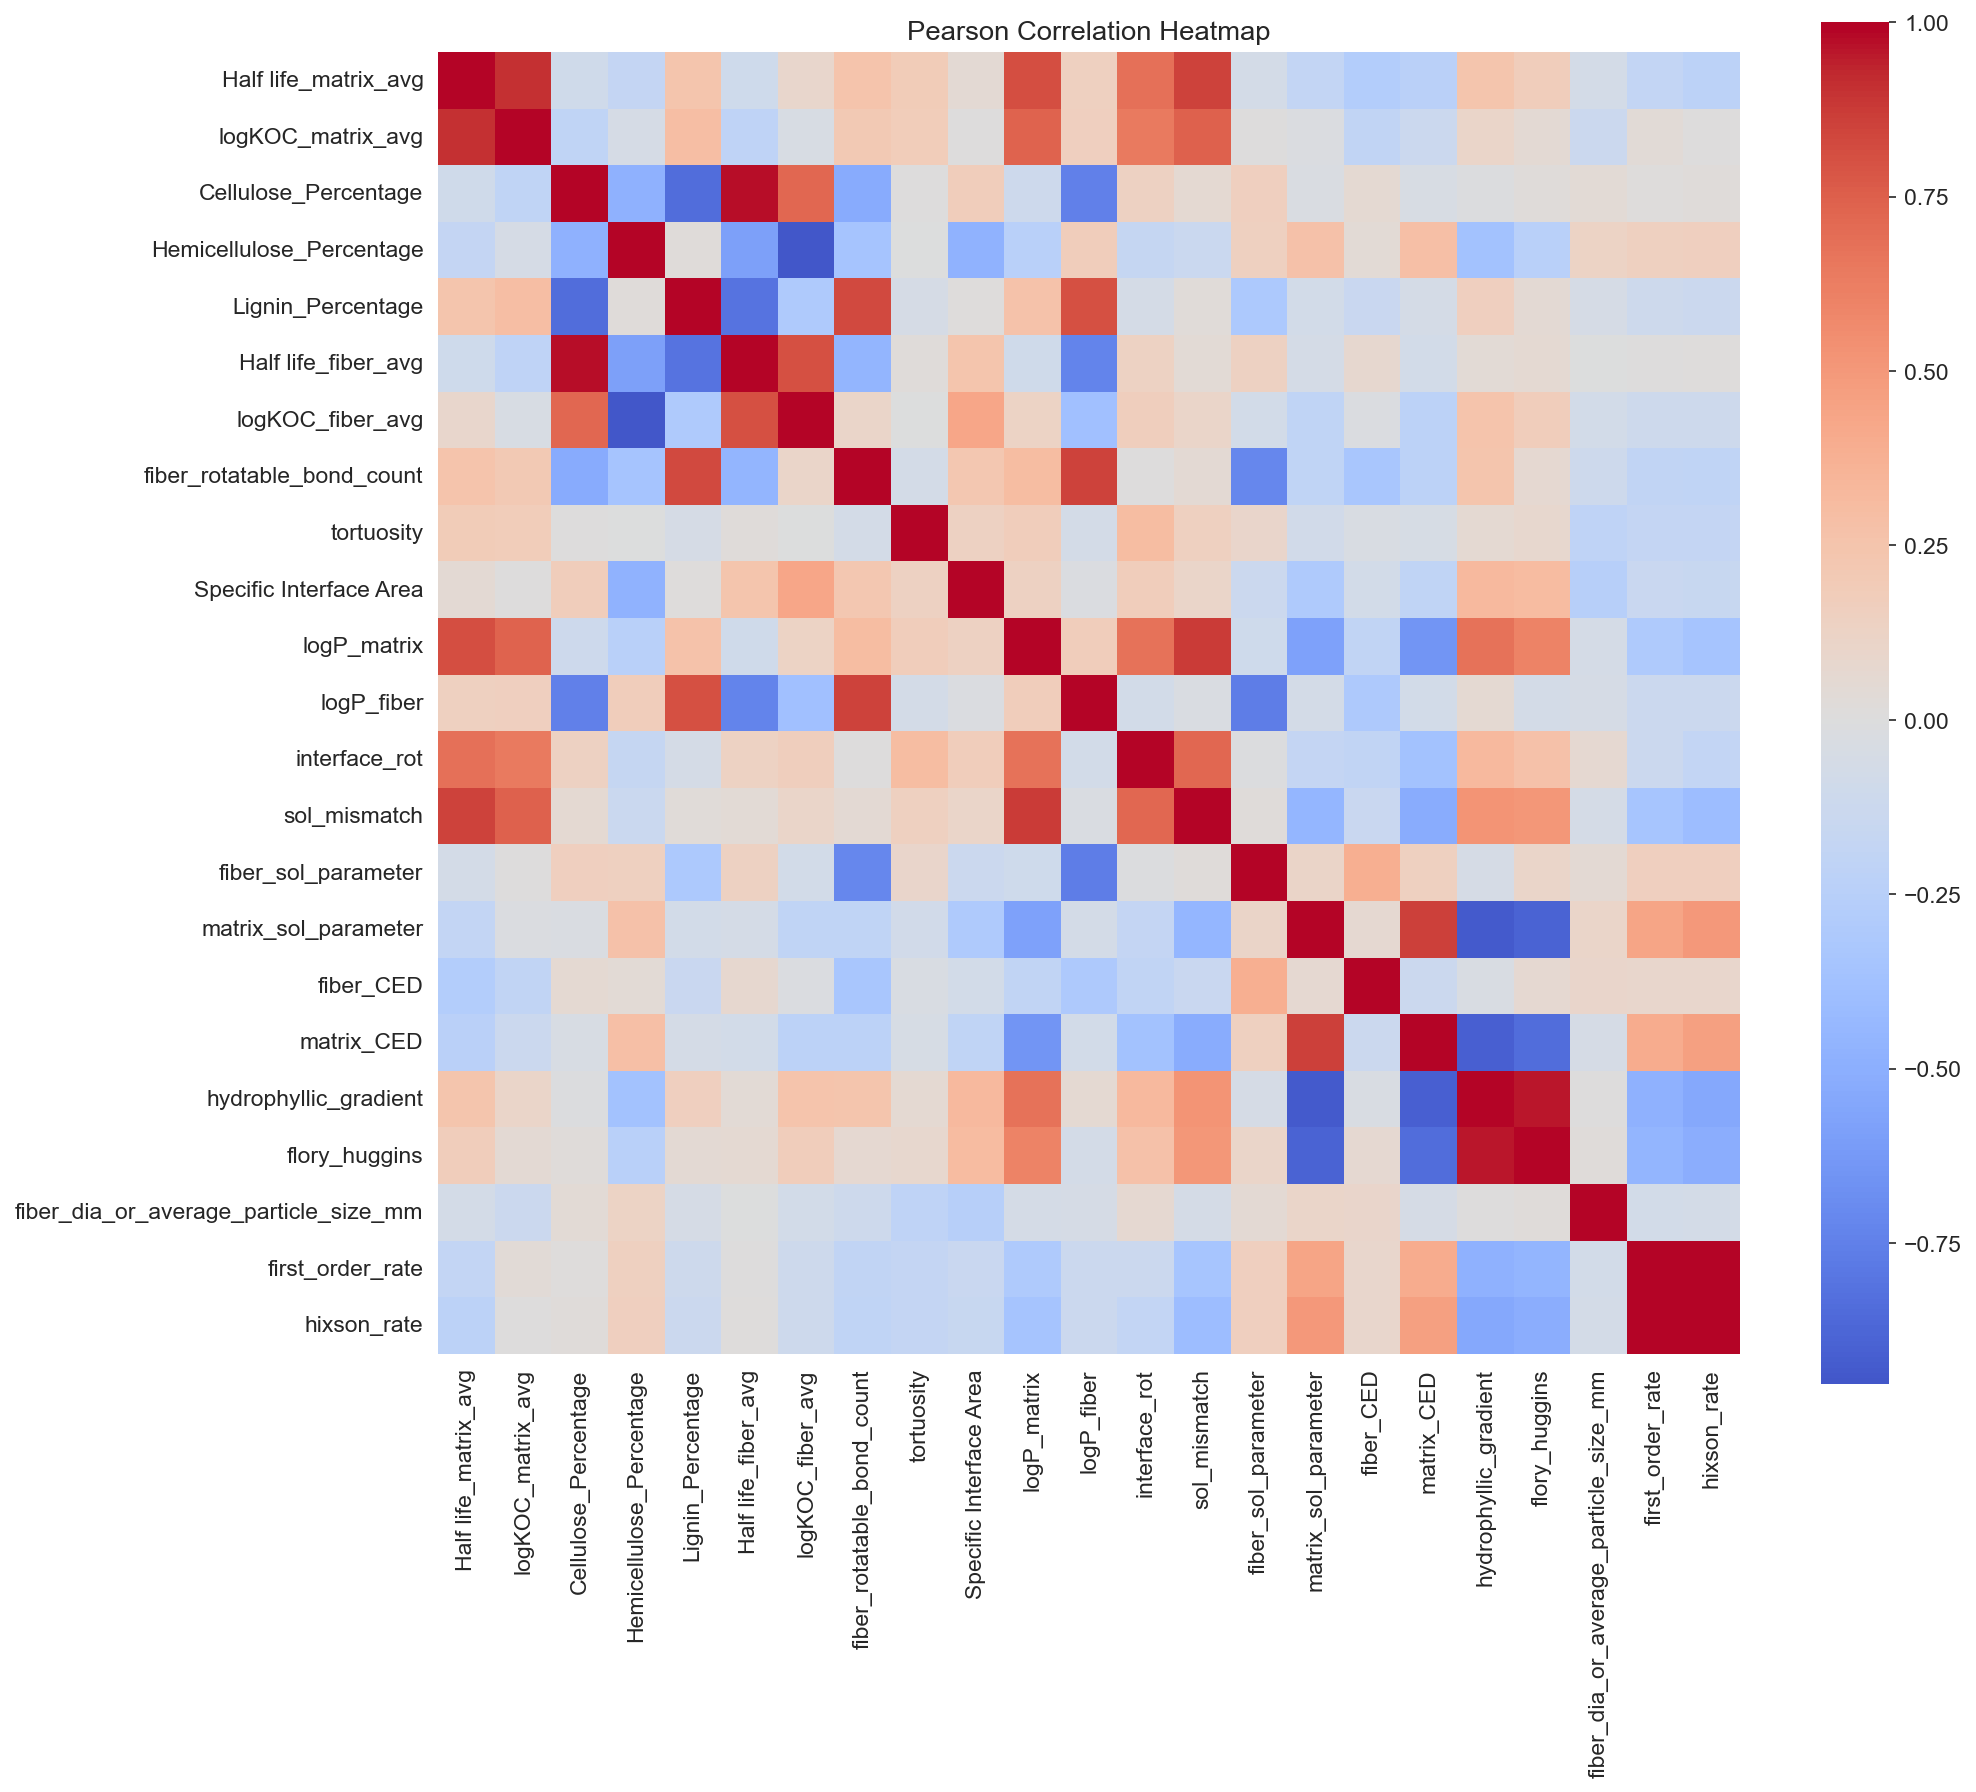

In [25]:
corr = numeric_df.corr(method='pearson')

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    annot=False,
    square=True
)

plt.title('Pearson Correlation Heatmap')

plt.tight_layout()
plt.savefig('pearson_heatmap.png', bbox_inches='tight')
plt.show()


# 5. Spearman Correlation Heatmap




🚀 Universal Vector Export: spearman_heatmap.svg


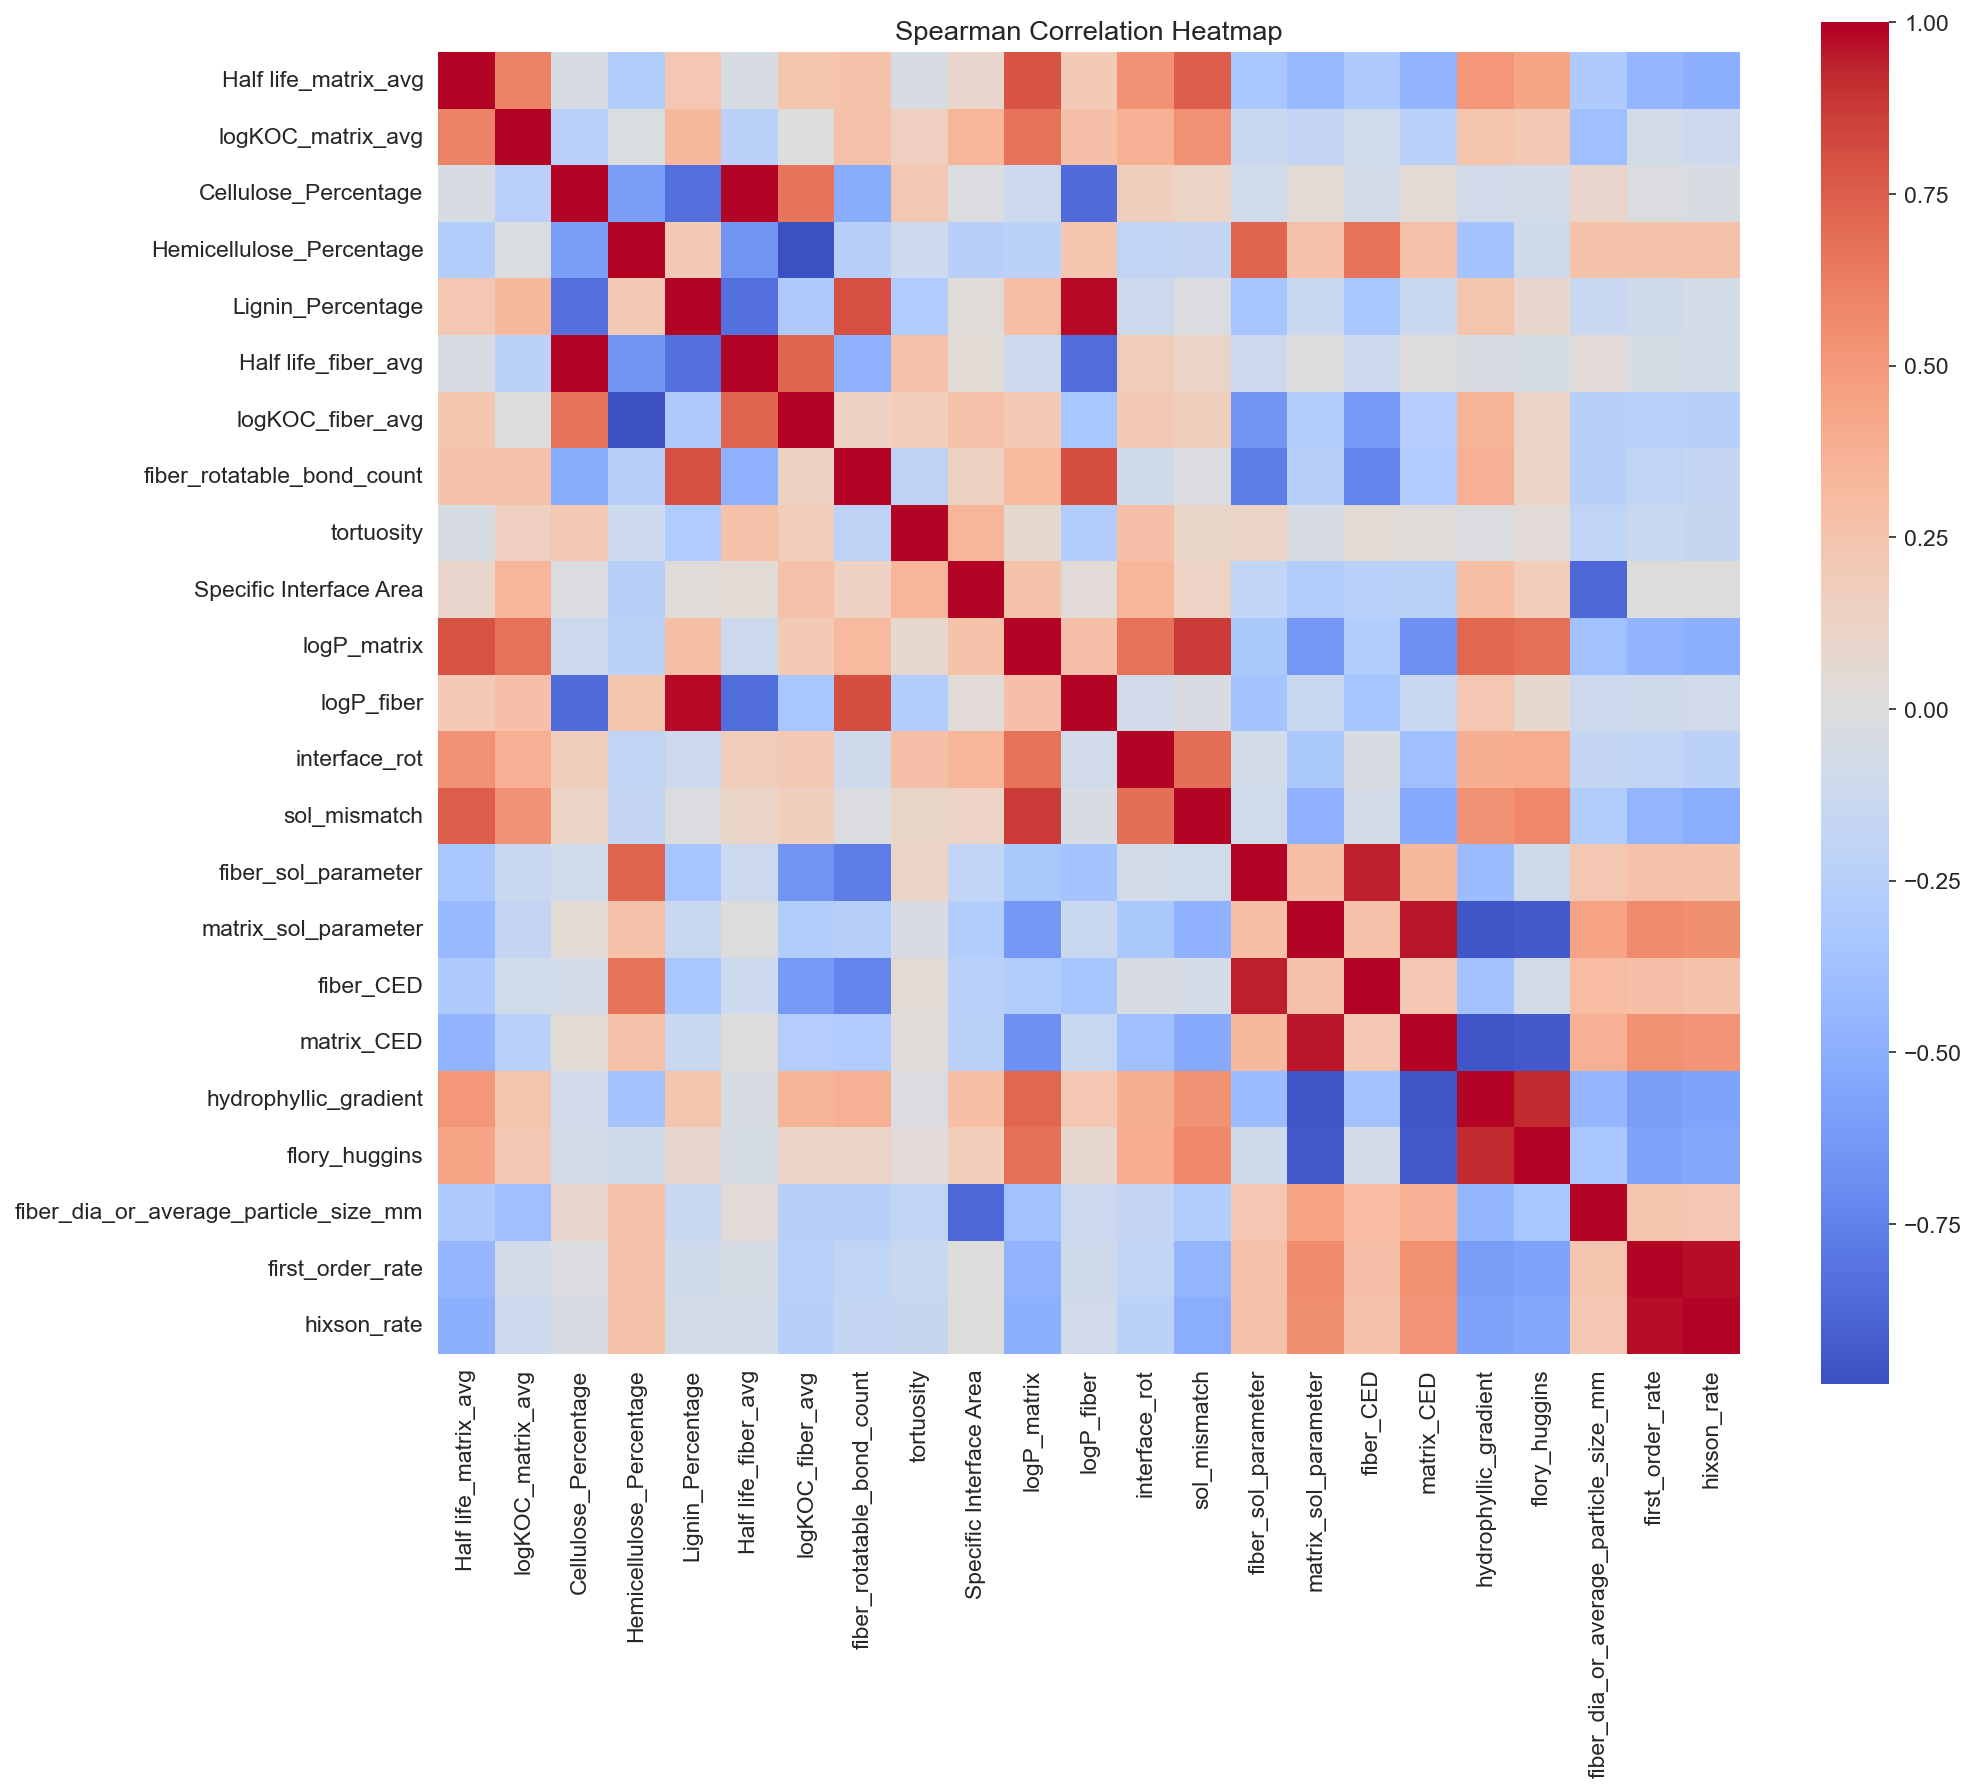

In [26]:
corr_s = numeric_df.corr(method='spearman')

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_s,
    cmap='coolwarm',
    center=0,
    annot=False,
    square=True
)

plt.title('Spearman Correlation Heatmap')

plt.tight_layout()
plt.savefig('spearman_heatmap.png', bbox_inches='tight')
plt.show()


# 6. PCA Chemical Space Analysis

🚀 Universal Vector Export: pca_chemical_space.svg


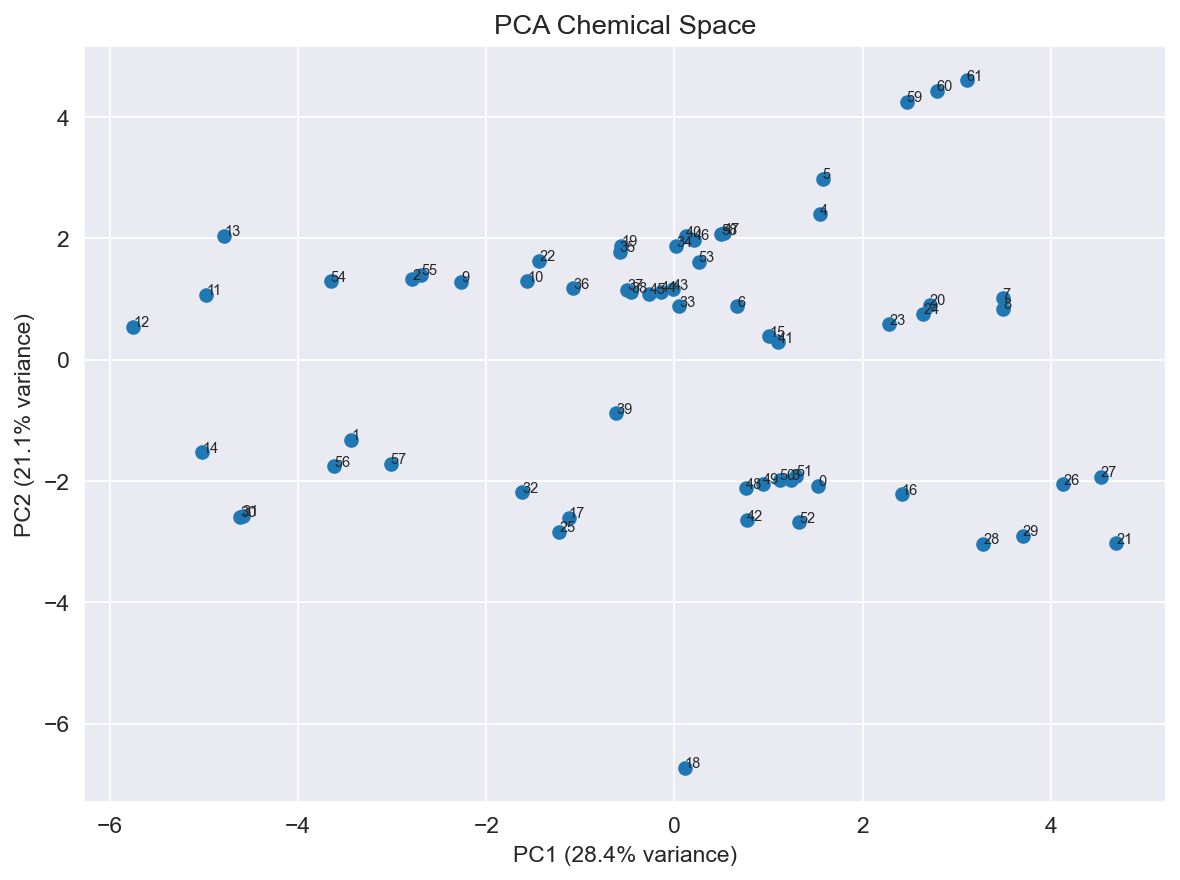

Explained variance ratios:
[0.28405764 0.21063266]


In [27]:
X = numeric_df.copy()

imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])

plt.figure(figsize=(8,6))
plt.scatter(pca_df['PC1'], pca_df['PC2'])

for i in range(len(pca_df)):
    plt.text(
        pca_df['PC1'][i],
        pca_df['PC2'][i],
        str(i),
        fontsize=7
    )

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.title('PCA Chemical Space')

plt.tight_layout()
plt.savefig('pca_chemical_space.png', bbox_inches='tight')
plt.show()

print('Explained variance ratios:')
print(pca.explained_variance_ratio_)


# 7. PCA Loading Plot

Shows which descriptors dominate the chemical space.


🚀 Universal Vector Export: pca_loading_plot.svg


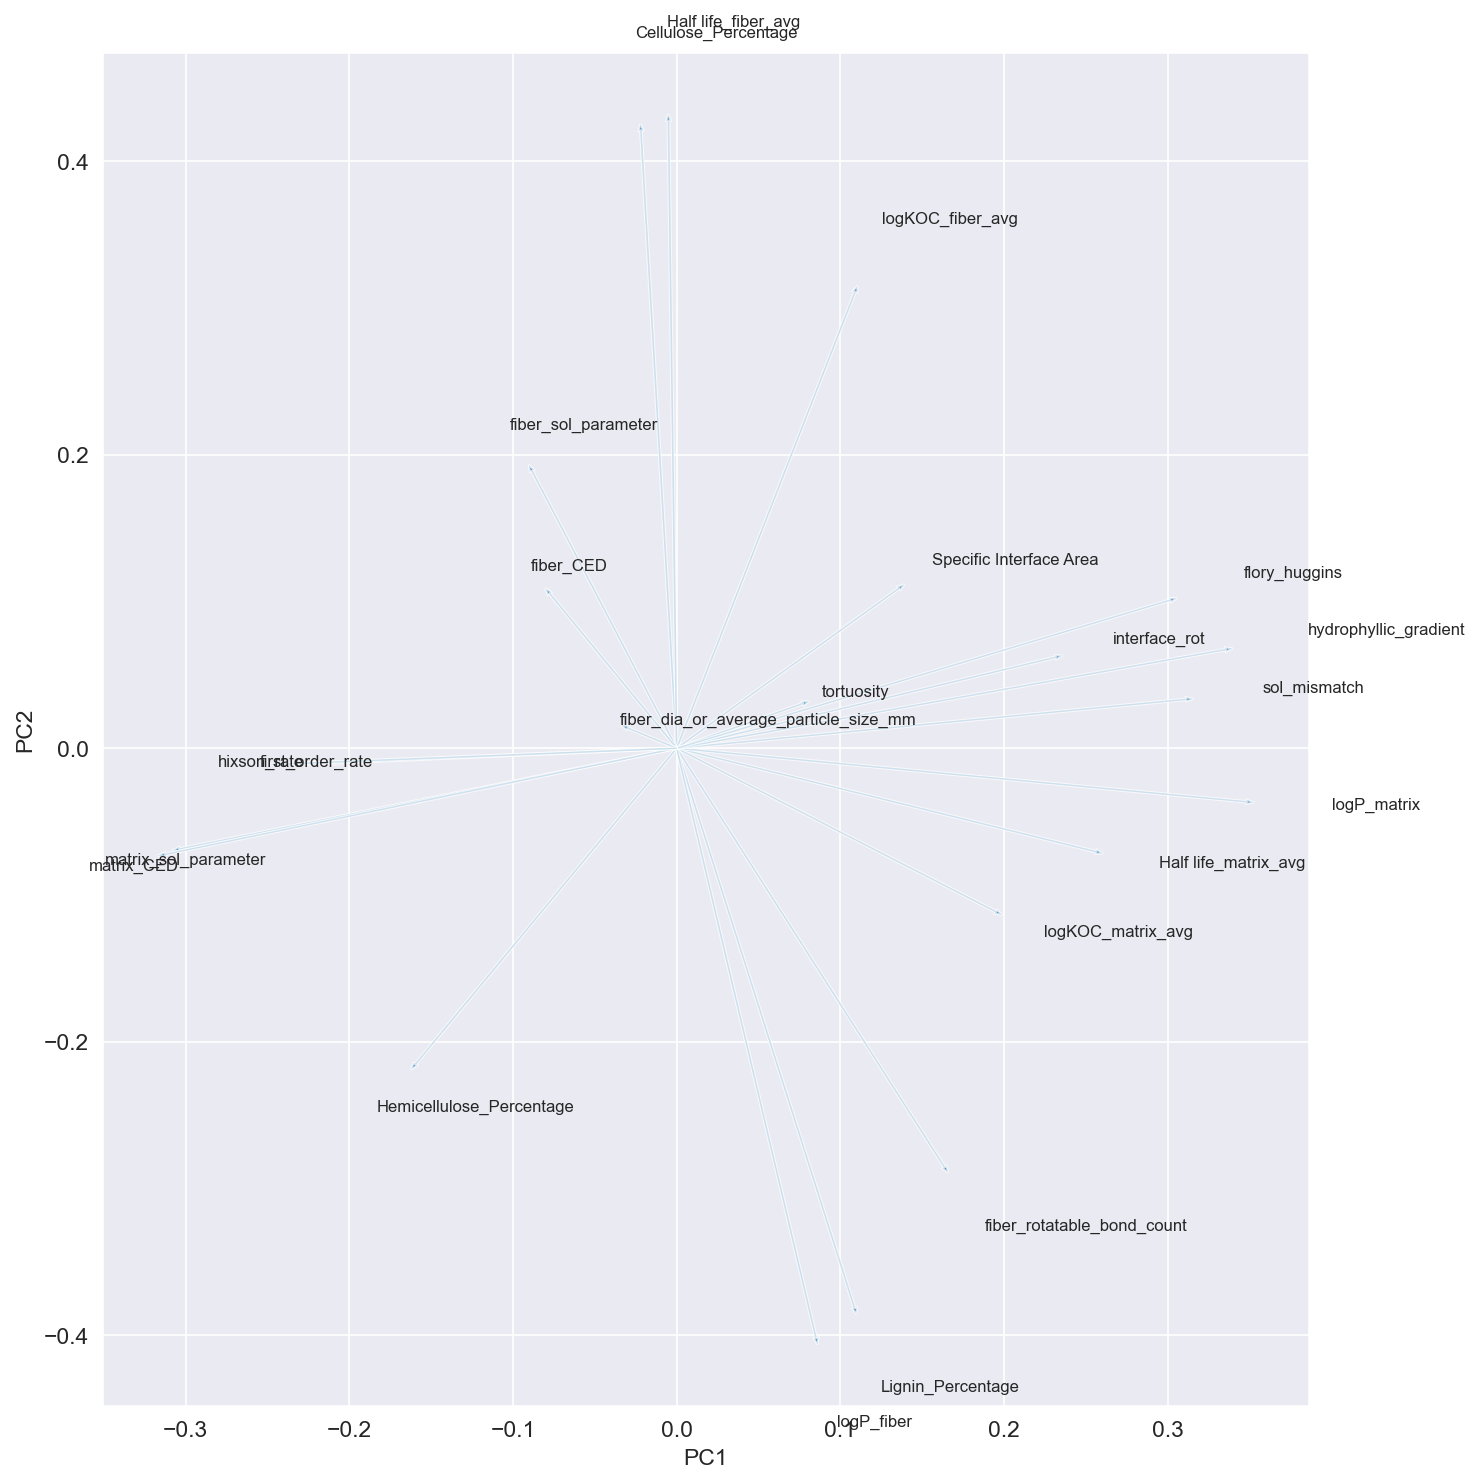

In [28]:
loadings = pca.components_.T

plt.figure(figsize=(10,10))

for i, feature in enumerate(numeric_df.columns):
    plt.arrow(
        0, 0,
        loadings[i,0],
        loadings[i,1],
        alpha=0.7
    )

    plt.text(
        loadings[i,0]*1.15,
        loadings[i,1]*1.15,
        feature,
        fontsize=8
    )
plt.xlabel('PC1')
plt.ylabel('PC2')
#plt.title('PCA Loading Plot')

plt.grid(True)
plt.tight_layout()

plt.savefig('pca_loading_plot.png', bbox_inches='tight')
plt.show()


# 8. UMAP Chemical Space Visualization

🚀 Universal Vector Export: umap_chemical_space.svg


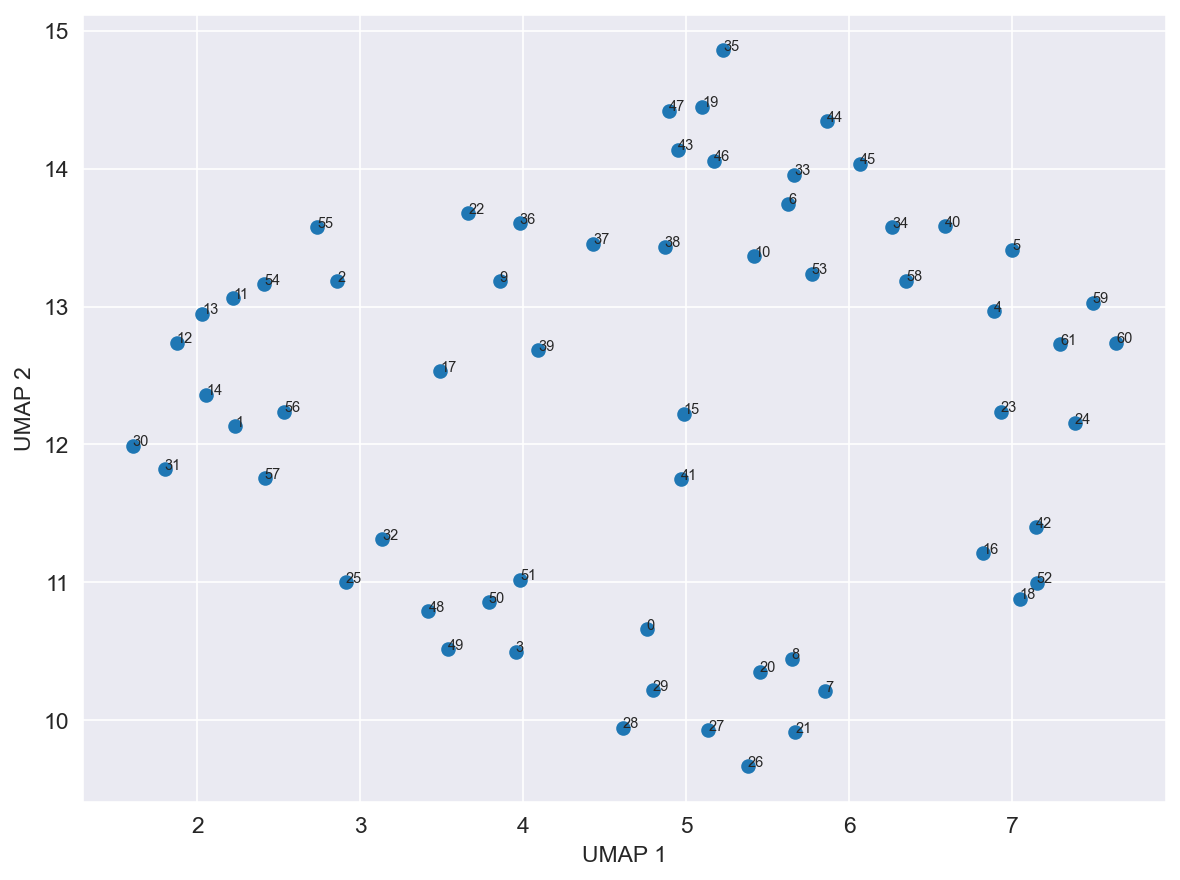

In [29]:
try:
    import umap

    reducer = umap.UMAP(
        n_neighbors=10,
        min_dist=0.2,
        random_state=42
    )

    X_umap = reducer.fit_transform(X_scaled)

    plt.figure(figsize=(8,6))
    plt.scatter(X_umap[:,0], X_umap[:,1])

    for i in range(len(X_umap)):
        plt.text(
            X_umap[i,0],
            X_umap[i,1],
            str(i),
            fontsize=7
        )

    #plt.title('UMAP Chemical Space')
    plt.xlabel('UMAP 1')
    plt.ylabel('UMAP 2')
    plt.tight_layout()
    plt.savefig('umap_chemical_space.png', bbox_inches='tight')
    plt.show()

except Exception as e:
    print('UMAP not installed or failed:', e)


# 9. Pairwise Descriptor Relationships

🚀 Universal Vector Export: pairplot.svg


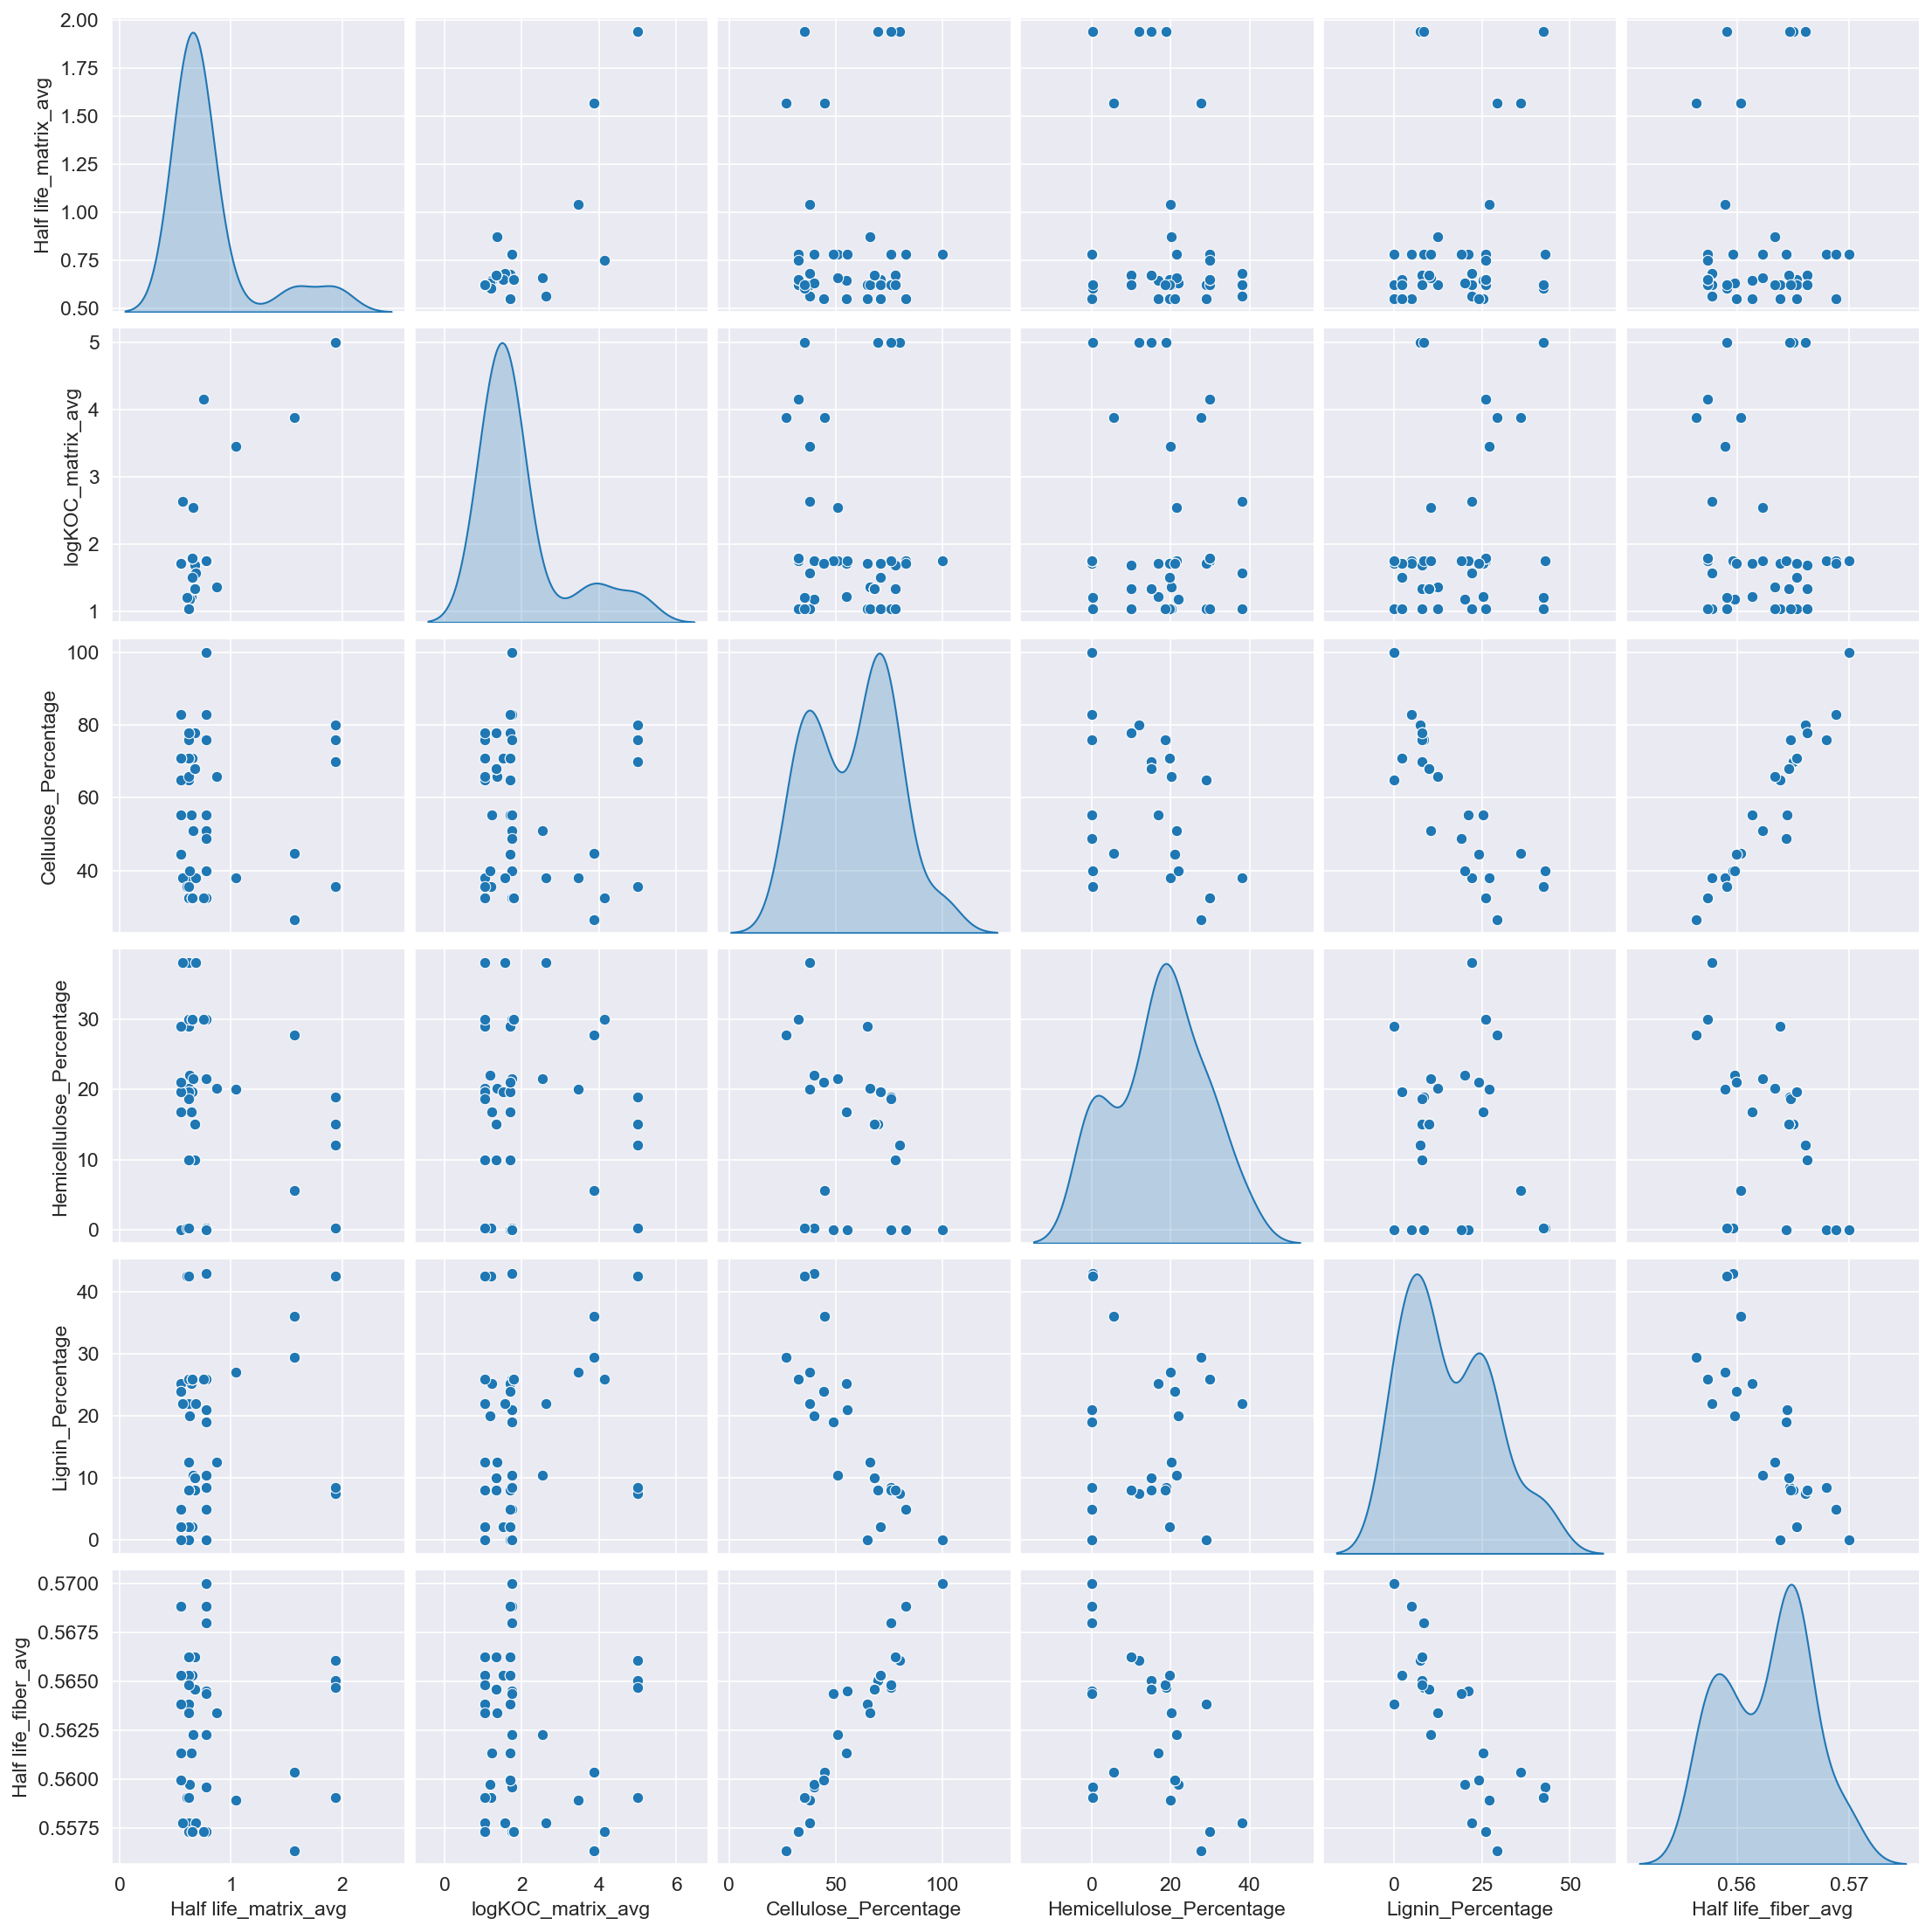

In [30]:
top_features = numeric_df.columns[:6]

sns.pairplot(
    numeric_df[top_features],
    diag_kind='kde'
)

plt.savefig('pairplot.png', bbox_inches='tight')
plt.show()


# 10. Mahalanobis Distance Outlier Analysis

🚀 Universal Vector Export: mahalanobis_outliers.svg


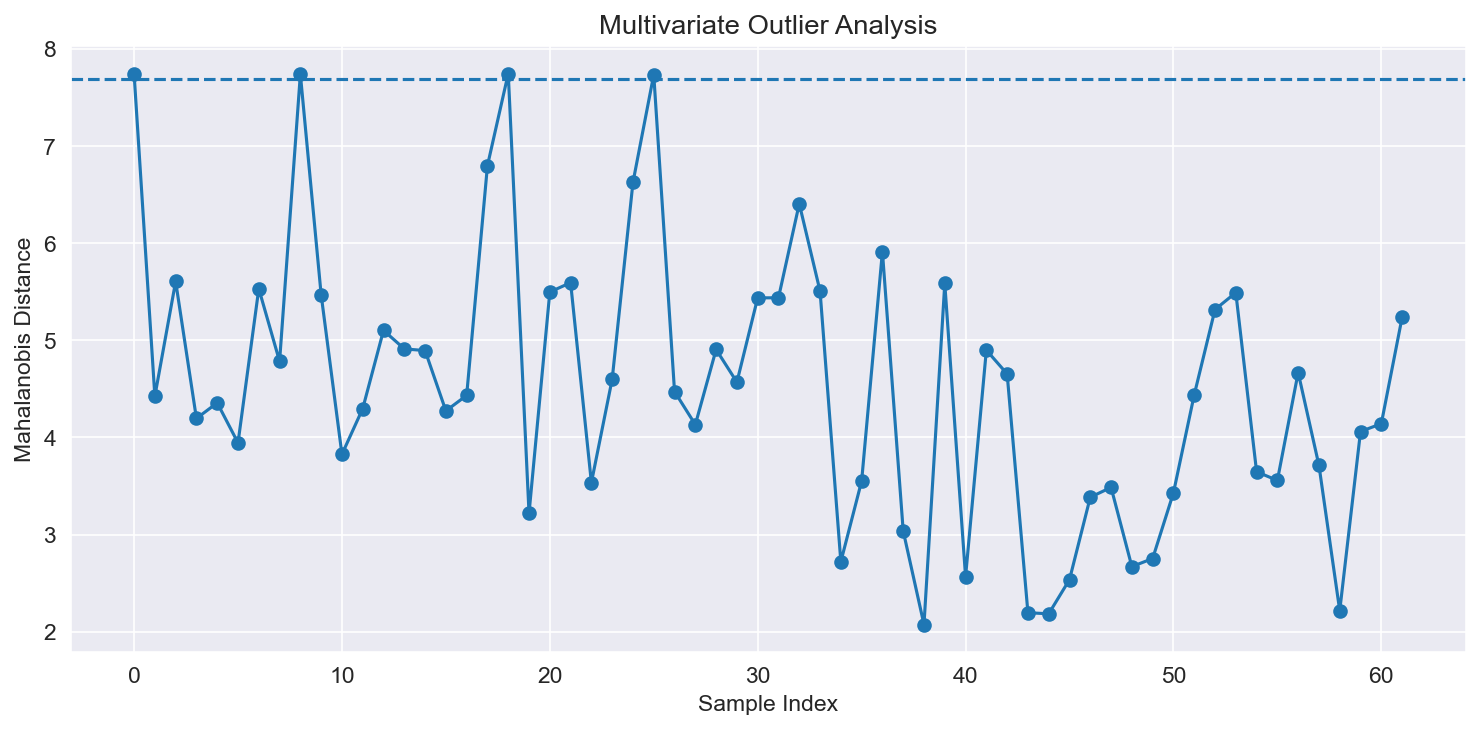

,Sample,Mahalanobis Distance
18,18,7.745910
0,0,7.745718
8,8,7.739153
25,25,7.733911
17,17,6.797618


In [31]:
X_md = X_scaled

cov_matrix = np.cov(X_md.T)
inv_cov_matrix = inv(cov_matrix)

mean_distr = X_md.mean(axis=0)

distances = []

for i in range(len(X_md)):
    dist = mahalanobis(
        X_md[i],
        mean_distr,
        inv_cov_matrix
    )
    distances.append(dist)

md_df = pd.DataFrame({
    'Sample': np.arange(len(distances)),
    'Mahalanobis Distance': distances
})

threshold = np.percentile(distances, 95)

plt.figure(figsize=(10,5))
plt.plot(distances, marker='o')

plt.axhline(
    threshold,
    linestyle='--'
)

plt.xlabel('Sample Index')
plt.ylabel('Mahalanobis Distance')
plt.title('Multivariate Outlier Analysis')

plt.tight_layout()
plt.savefig('mahalanobis_outliers.png', bbox_inches='tight')
plt.show()

display(md_df.sort_values('Mahalanobis Distance', ascending=False).head())


# 11. Variance Analysis

Shows which descriptors dominate variability.


🚀 Universal Vector Export: descriptor_variance.svg


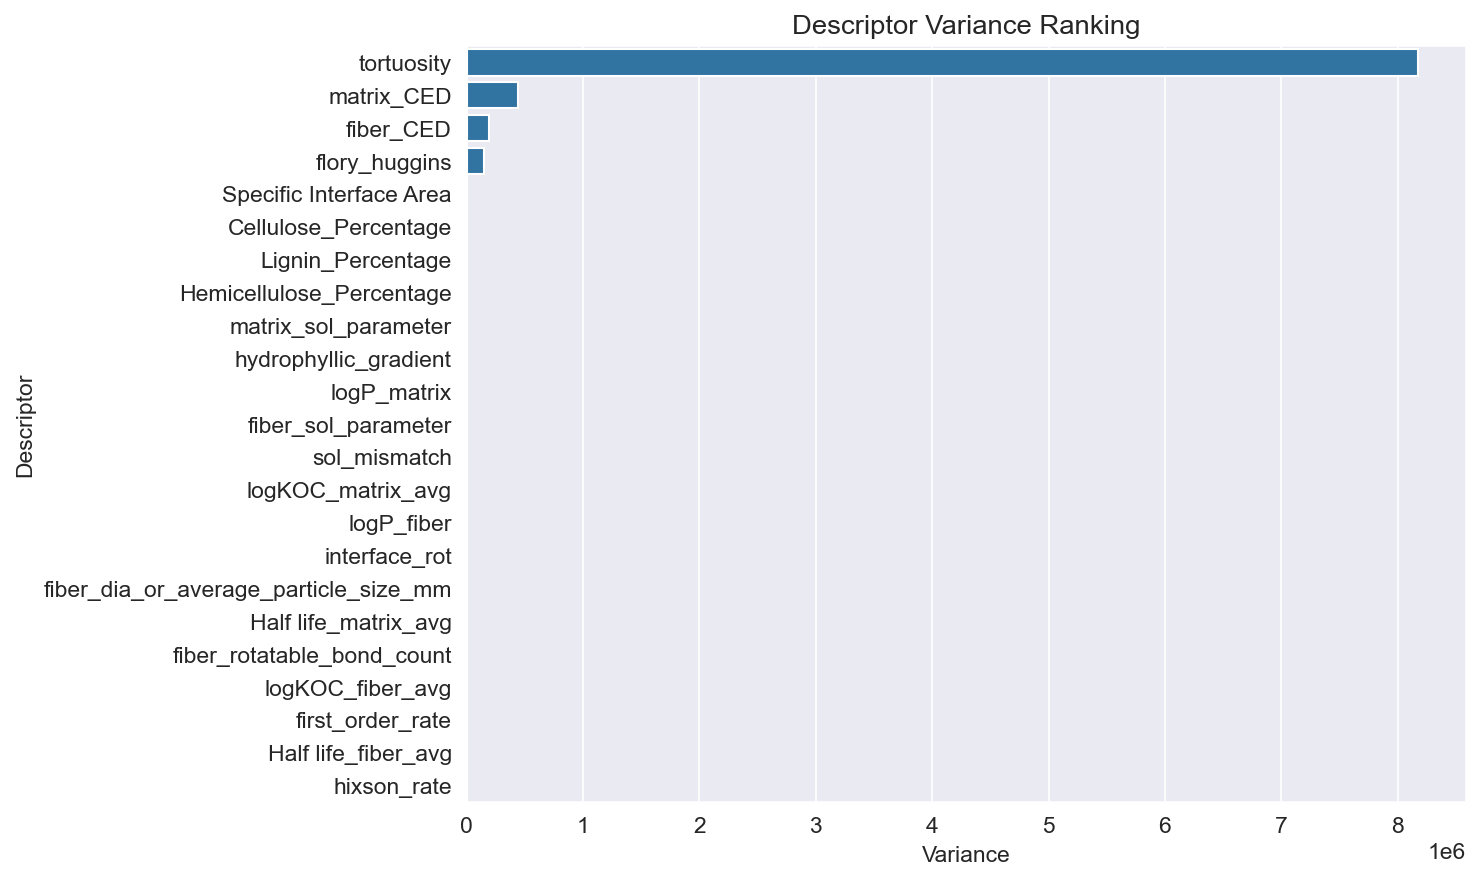

,Descriptor,Variance
8,tortuosity,8.173584e+06
17,matrix_CED,4.451653e+05
16,fiber_CED,1.961597e+05
19,flory_huggins,1.545392e+05
9,Specific Interface Area,1.686706e+03
2,Cellulose_Percentage,3.864320e+02
4,Lignin_Percentage,1.553683e+02
3,Hemicellulose_Percentage,1.268916e+02
15,matrix_sol_parameter,1.079304e+02
18,hydrophyllic_gradient,1.035570e+02


In [32]:
variance_df = pd.DataFrame({
    'Descriptor': numeric_df.columns,
    'Variance': numeric_df.var().values
}).sort_values('Variance', ascending=False)

plt.figure(figsize=(10,6))

sns.barplot(
    data=variance_df,
    x='Variance',
    y='Descriptor'
)

plt.title('Descriptor Variance Ranking')

plt.tight_layout()
plt.savefig('descriptor_variance.png', bbox_inches='tight')
plt.show()

display(variance_df)


In [35]:
corr.to_csv('pearson_correlation_matrix.csv')
corr_s.to_csv('spearman_correlation_matrix.csv')
variance_df.to_csv('descriptor_variance.csv', index=False)
md_df.to_csv('mahalanobis_distances.csv', index=False)

print('All tables exported successfully.')


All tables exported successfully.
